In [2]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, roc_curve
import matplotlib.pyplot as plt
import os
DATOS = "../../Practicas_IA_Explicable_practicantes/german_credit.csv"
print("¿El archivo existe?:", os.path.exists(DATOS))

datos_df = pd.read_csv(DATOS)

¿El archivo existe?: True


In [7]:
X_explicativas = datos_df.drop(columns=["class"]).copy()
y_texto = datos_df["class"].copy()
Y_target = (y_texto == "bad").astype(int)

var_genero = 'personal_status'
variables_control = [
    'duration', 'credit_amount', 'installment_commitment',
    'age', 'existing_credits', 'num_dependents'
]

X_explicativas['is_male_single'] = (X_explicativas[var_genero] == 'male single').astype(int)
X_explicativas['is_male_div_sep'] = (X_explicativas[var_genero] == 'male div/sep').astype(int)
X_explicativas['is_male_mar_wid'] = (X_explicativas[var_genero] == 'male mar/wid').astype(int)

columnas_genero_dummies = ['is_male_single', 'is_male_div_sep', 'is_male_mar_wid']

X_modelo = pd.concat([X_explicativas[variables_control], X_explicativas[columnas_genero_dummies]], axis=1)

X_modelo = sm.add_constant(X_modelo)

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X_modelo, Y_target, 
    test_size=0.20, 
    random_state=42,
    stratify=Y_target
)

X_train_con = X_train.copy()
X_test_con = X_test.copy()

X_train_sin = X_train.drop(columns=columnas_genero_dummies)
X_test_sin = X_test.drop(columns=columnas_genero_dummies)

print(f"\nMuestra de entrenamiento: {X_train.shape[0]} observaciones")
print(f"Muestra de prueba (pronóstico): {X_test.shape[0]} observaciones\n")

# ==========================================
# MODELO 1: CON VARIABLES DE GÉNERO
# ==========================================
print("="*50)
print("  ESTIMANDO MODELO 1: CON GÉNERO (BENCHMARK)")
print("="*50)
modelo_con_genero = sm.Logit(y_train, X_train_con).fit()
print(modelo_con_genero.summary())

# Pronóstico fuera de muestra (Test Set)
preds_con = modelo_con_genero.predict(X_test_con)
auc_con = roc_auc_score(y_test, preds_con)
gini_con = 2 * auc_con - 1

# ==========================================
# MODELO 2: SIN VARIABLES DE GÉNERO
# ==========================================
print("\n" + "="*50)
print("  ESTIMANDO MODELO 2: SIN GÉNERO (CIEGO)")
print("="*50)
modelo_sin_genero = sm.Logit(y_train, X_train_sin).fit()
print(modelo_sin_genero.summary())

# Pronóstico fuera de muestra (Test Set)
preds_sin = modelo_sin_genero.predict(X_test_sin)
auc_sin = roc_auc_score(y_test, preds_sin)
gini_sin = 2 * auc_sin - 1


Muestra de entrenamiento: 800 observaciones
Muestra de prueba (pronóstico): 200 observaciones

  ESTIMANDO MODELO 1: CON GÉNERO (BENCHMARK)
Optimization terminated successfully.
         Current function value: 0.572595
         Iterations 5
                           Logit Regression Results                           
Dep. Variable:                  class   No. Observations:                  800
Model:                          Logit   Df Residuals:                      790
Method:                           MLE   Df Model:                            9
Date:                Thu, 11 Jun 2026   Pseudo R-squ.:                 0.06265
Time:                        20:25:50   Log-Likelihood:                -458.08
converged:                       True   LL-Null:                       -488.69
Covariance Type:            nonrobust   LLR p-value:                 7.757e-10
                             coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------

In [10]:
print("="*50)
print("  ESTIMANDO MODELO 3: PROBIT CON GÉNERO")
print("="*50)
# Estimamos el Probit con la variable sensible utilizando Máxima Verosimilitud
probit_con = sm.Probit(y_train, X_train_con).fit()
print(probit_con.summary())

# Pronóstico fuera de muestra (Test Set)
preds_probit_con = probit_con.predict(X_test_con)
auc_p_con = roc_auc_score(y_test, preds_probit_con)
gini_p_con = 2 * auc_p_con - 1

print("\n" + "="*50)
print("  ESTIMANDO MODELO 4: PROBIT SIN GÉNERO (CIEGO)")
print("="*50)
# Estimamos el Probit ciego
probit_sin = sm.Probit(y_train, X_train_sin).fit()
print(probit_sin.summary())

# Pronóstico fuera de muestra (Test Set)
preds_probit_sin = probit_sin.predict(X_test_sin)
auc_p_sin = roc_auc_score(y_test, preds_probit_sin)
gini_p_sin = 2 * auc_p_sin - 1

  ESTIMANDO MODELO 3: PROBIT CON GÉNERO
Optimization terminated successfully.
         Current function value: 0.572488
         Iterations 5
                          Probit Regression Results                           
Dep. Variable:                  class   No. Observations:                  800
Model:                         Probit   Df Residuals:                      790
Method:                           MLE   Df Model:                            9
Date:                Thu, 11 Jun 2026   Pseudo R-squ.:                 0.06282
Time:                        20:36:51   Log-Likelihood:                -457.99
converged:                       True   LL-Null:                       -488.69
Covariance Type:            nonrobust   LLR p-value:                 7.190e-10
                             coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------
const                     -1.1909      0.283

In [14]:
print("\n" + "==================================================")
print("   CUADRO COMPARATIVO GLOBAL (FUERA DE MUESTRA)   ")
print("==================================================")
print(f"1. LOGIT Con Género -> AUC: {auc_con:.4f} | Gini: {gini_con:.4f}")
print(f"2. LOGIT Sin Género -> AUC: {auc_sin:.4f} | Gini: {gini_sin:.4f}")
print("-" * 50)
print(f"3. PROBIT Con Género -> AUC: {auc_p_con:.4f} | Gini: {gini_p_con:.4f}")
print(f"4. PROBIT Sin Género -> AUC: {auc_p_sin:.4f} | Gini: {gini_p_sin:.4f}")
print("==================================================")


   CUADRO COMPARATIVO GLOBAL (FUERA DE MUESTRA)   
1. LOGIT Con Género -> AUC: 0.6770 | Gini: 0.3540
2. LOGIT Sin Género -> AUC: 0.6874 | Gini: 0.3748
--------------------------------------------------
3. PROBIT Con Género -> AUC: 0.6773 | Gini: 0.3545
4. PROBIT Sin Género -> AUC: 0.6870 | Gini: 0.3740


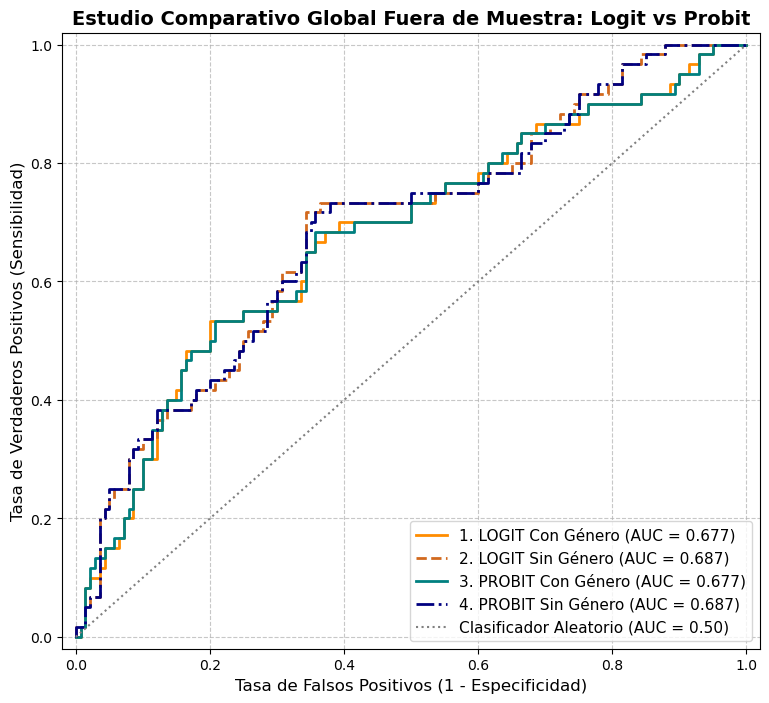

In [16]:
fpr_log_con, tpr_log_con, _ = roc_curve(y_test, preds_con)
fpr_log_sin, tpr_log_sin, _ = roc_curve(y_test, preds_sin)

fpr_prob_con, tpr_prob_con, _ = roc_curve(y_test, preds_probit_con)
fpr_prob_sin, tpr_prob_sin, _ = roc_curve(y_test, preds_probit_sin)

plt.figure(figsize=(9, 8))

plt.plot(fpr_log_con, tpr_log_con, label=f'1. LOGIT Con Género (AUC = {auc_con:.3f})', color='darkorange', lw=2)
plt.plot(fpr_log_sin, tpr_log_sin, label=f'2. LOGIT Sin Género (AUC = {auc_sin:.3f})', color='chocolate', lw=2, linestyle='--')

plt.plot(fpr_prob_con, tpr_prob_con, label=f'3. PROBIT Con Género (AUC = {auc_p_con:.3f})', color='teal', lw=2)
plt.plot(fpr_prob_sin, tpr_prob_sin, label=f'4. PROBIT Sin Género (AUC = {auc_p_sin:.3f})', color='navy', lw=2, linestyle='-.')

plt.plot([0, 1], [0, 1], color='gray', linestyle=':', label='Clasificador Aleatorio (AUC = 0.50)')

plt.xlim([-0.02, 1.02])
plt.ylim([-0.02, 1.02])
plt.xlabel('Tasa de Falsos Positivos (1 - Especificidad)', fontsize=12)
plt.ylabel('Tasa de Verdaderos Positivos (Sensibilidad)', fontsize=12)
plt.title('Estudio Comparativo Global Fuera de Muestra: Logit vs Probit', fontsize=14, fontweight='bold')
plt.legend(loc="lower right", fontsize=11)
plt.grid(True, linestyle='--', alpha=0.7)
plt.savefig('Estudio_Comparativo_Global.png', dpi=300, bbox_inches='tight')
plt.show()